# Lab 2 · Part I: Neural Networks and Regression

We fit small fully connected networks (MLPs) to
- **(a)** a synthetic 1-D polynomial, and
- **(b)** a real UCI regression dataset (Concrete Compressive Strength),

and look at how depth, width, activation, weight decay and the complexity of the target change the fit.
For regression, "accuracy" means **MSE** (the training loss) and **R²**, both on train and test.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

torch.manual_seed(0)
torch.set_num_threads(4)  # tiny models: CPU beats GPU/MPS here
pd.options.display.float_format = "{:.4g}".format
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Polynomial toy data

`eval_poly(x, c)` evaluates an order-$p$ polynomial (Horner's rule). A polynomial with random coefficients is almost
flat on $[-1, 1]$ for large $p$, so `random_poly` instead puts the $p$ roots at slightly jittered Chebyshev nodes.
That way a higher order really means more wiggles ($p-1$ turning points over the whole interval). Each polynomial
is scaled to $\max_{[-1,1]}|f| = 1$, so MSEs are comparable across $p$.

Data:
- 1,000 points, $x \sim U(-1, 1)$
- $y = f(x) + \varepsilon$, $\varepsilon \sim \mathcal N(0, 0.02^2)$
- 80/20 train/test split
- the noise variance $4\cdot10^{-4}$ is the best test MSE we can hope for

p = 3 coefficients, highest degree first: [ 2.355 -0.308 -1.55   0.113]
800 training / 200 test points
noise-only MSE (true f vs data): train 4.02e-04 | test 4.96e-04


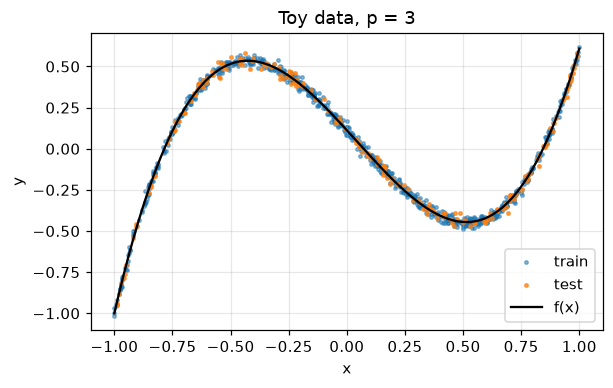

In [2]:
def eval_poly(x, c):
    # Horner's rule, c[0] is the highest-degree coefficient
    out = np.zeros_like(x, dtype=float)
    for ck in c:
        out = out * x + ck
    return out

def random_poly(p, seed=0):
    rng = np.random.default_rng(seed)
    k = np.arange(1, p + 1)
    roots = np.cos((2 * k - 1 + rng.uniform(-0.3, 0.3, p)) * np.pi / (2 * p))
    c = np.poly(roots)
    return c / np.abs(eval_poly(np.linspace(-1, 1, 2001), c)).max()

SIGMA = 0.02

def col(a):
    t = torch.tensor(np.asarray(a), dtype=torch.float32)
    return t.unsqueeze(1) if t.ndim == 1 else t

def toy_data(p, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    c = random_poly(p, seed)
    x = rng.uniform(-1, 1, n)
    y = eval_poly(x, c) + SIGMA * rng.standard_normal(n)
    x_a, x_b, y_a, y_b = train_test_split(x, y, test_size=0.2, random_state=seed)
    return c, tuple(map(col, (x_a, y_a, x_b, y_b)))

poly_c, toy = toy_data(p=3)
Xtr, ytr, Xte, yte = toy
print("p = 3 coefficients, highest degree first:", np.round(poly_c, 3))
print(f"{len(Xtr)} training / {len(Xte)} test points")
true_mse = lambda X, y: np.mean((eval_poly(X[:, 0].numpy(), poly_c) - y[:, 0].numpy()) ** 2)
print(f"noise-only MSE (true f vs data): train {true_mse(Xtr, ytr):.2e} | test {true_mse(Xte, yte):.2e}")

xs = np.linspace(-1, 1, 400)
plt.figure(figsize=(6, 3.5))
plt.scatter(Xtr, ytr, s=5, alpha=0.5, label="train")
plt.scatter(Xte, yte, s=5, alpha=0.7, label="test")
plt.plot(xs, eval_poly(xs, poly_c), "k", lw=1.5, label="f(x)")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Toy data, p = 3"); plt.legend()
plt.show()

## 2. The network before training

`FeedForward` stacks `Linear` layers of width $m$ with an activation in between and a linear output. Default:
2 hidden layers, $m = 64$, ReLU, PyTorch's default random (Kaiming-uniform) initialization.

FeedForward(
  (body): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
trainable parameters: 4353


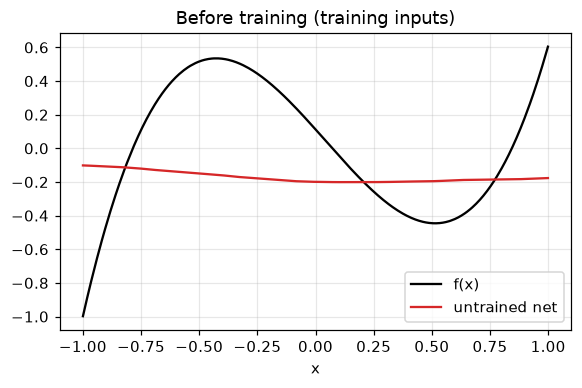

MSE before training: 0.1649


In [3]:
class FeedForward(nn.Module):
    def __init__(self, d_in=1, widths=(64, 64), act=nn.ReLU):
        super().__init__()
        blocks, d = [], d_in
        for w in widths:
            blocks += [nn.Linear(d, w), act()]
            d = w
        blocks.append(nn.Linear(d, 1))
        self.body = nn.Sequential(*blocks)

    def forward(self, x):
        return self.body(x)

def count_params(net):
    return sum(w.numel() for w in net.parameters())

torch.manual_seed(0)
net = FeedForward()
print(net)
print("trainable parameters:", count_params(net))

srt = Xtr[:, 0].argsort()
with torch.no_grad():
    out0 = net(Xtr)
plt.figure(figsize=(6, 3.5))
plt.plot(Xtr[srt], eval_poly(Xtr[srt, 0].numpy(), poly_c), "k", label="f(x)")
plt.plot(Xtr[srt], out0[srt], "C3", label="untrained net")
plt.xlabel("x"); plt.title("Before training (training inputs)"); plt.legend()
plt.show()
print(f"MSE before training: {F.mse_loss(out0, ytr).item():.4f}")

**Observations.** The untrained net is basically a flat, slightly tilted line. Its output is small and only mildly
piecewise linear in $x$, and it has nothing to do with $f$: its MSE is about $\mathrm{Var}(y)$, same as guessing a constant.

## 3. Training with MSE

**Gradients:** `loss.backward()` does backpropagation, i.e. it applies the chain rule from the MSE loss back through
every layer and stores $\partial L/\partial\theta$ in each parameter's `.grad`.
**Updates:** mini-batches of 32 (reshuffled every epoch) with Adam, learning rate $10^{-3}$. Adam is SGD
($\theta \leftarrow \theta - \eta g$) with momentum and a per-parameter step size. Weight decay $\lambda$ just adds
$\lambda\theta$ to the gradient.

A quick check that autograd agrees with the hand-computed gradient of the last layer, and that an SGD step is $\theta - \eta g$:

In [4]:
torch.manual_seed(0)
chk = FeedForward()
xb, yb = Xtr[:32], ytr[:32]
feats = chk.body[:-1](xb)                   # input to the last Linear layer
F.mse_loss(chk(xb), yb).backward()
g_out = 2 / len(xb) * (chk(xb) - yb)        # dL/d(prediction)
W = chk.body[-1].weight
print("manual gradient == autograd:", torch.allclose(g_out.T @ feats, W.grad, atol=1e-6))

W_before = W.detach().clone()
torch.optim.SGD(chk.parameters(), lr=0.1).step()
print("SGD update == W - 0.1 * grad:", torch.allclose(W, W_before - 0.1 * W.grad))

manual gradient == autograd: True


SGD update == W - 0.1 * grad: True


`fit` records train/test MSE and R² after **every** epoch; we print some of the epochs and plot all of them.

ep   1  train: MSE 1.06e-01, R2 0.2378   test: MSE 1.24e-01, R2 0.1734
ep   2  train: MSE 8.17e-02, R2 0.4102   test: MSE 9.68e-02, R2 0.3569
ep   3  train: MSE 5.76e-02, R2 0.5842   test: MSE 6.79e-02, R2 0.5491
ep   4  train: MSE 3.28e-02, R2 0.7631   test: MSE 3.98e-02, R2 0.7354
ep   5  train: MSE 1.57e-02, R2 0.8866   test: MSE 2.12e-02, R2 0.8594
ep  25  train: MSE 9.64e-04, R2 0.9930   test: MSE 1.27e-03, R2 0.9916


ep  50  train: MSE 4.52e-04, R2 0.9967   test: MSE 5.89e-04, R2 0.9961
ep  75  train: MSE 5.05e-04, R2 0.9964   test: MSE 6.38e-04, R2 0.9958


ep 100  train: MSE 7.02e-04, R2 0.9949   test: MSE 7.52e-04, R2 0.9950
ep 125  train: MSE 5.25e-04, R2 0.9962   test: MSE 7.24e-04, R2 0.9952


ep 150  train: MSE 5.16e-04, R2 0.9963   test: MSE 6.30e-04, R2 0.9958
ep 175  train: MSE 4.66e-04, R2 0.9966   test: MSE 5.63e-04, R2 0.9963


ep 200  train: MSE 4.90e-04, R2 0.9965   test: MSE 6.43e-04, R2 0.9957


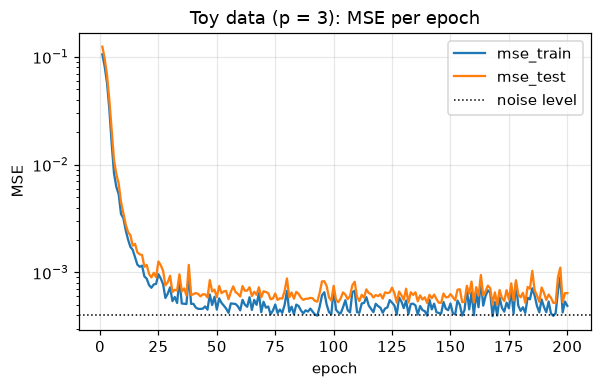

In [5]:
def score(net, X, y):
    net.eval()
    with torch.no_grad():
        mse = F.mse_loss(net(X), y).item()
    return mse, 1 - mse / y.var(unbiased=False).item()

def fit(net, splits, epochs=200, lr=1e-3, bs=32, wd=0.0, log_every=None):
    Xa, ya, Xb, yb = splits
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    rows = []
    for ep in range(1, epochs + 1):
        net.train()
        shuffle = torch.randperm(len(Xa))
        for s in range(0, len(Xa), bs):
            b = shuffle[s:s + bs]
            loss = F.mse_loss(net(Xa[b]), ya[b])
            opt.zero_grad(); loss.backward(); opt.step()
        rows.append((ep, *score(net, Xa, ya), *score(net, Xb, yb)))
        if log_every and (ep <= 5 or ep % log_every == 0):
            print("ep {:3d}  train: MSE {:.2e}, R2 {:.4f}   test: MSE {:.2e}, R2 {:.4f}".format(*rows[-1]))
    return pd.DataFrame(rows, columns=["epoch", "mse_train", "r2_train", "mse_test", "r2_test"]).set_index("epoch")

def plot_history(log, title, floor=None):
    ax = log[["mse_train", "mse_test"]].plot(logy=True, figsize=(6, 3.5), title=title)
    if floor:
        ax.axhline(floor, color="k", ls=":", lw=1, label="noise level")
    ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.legend()
    plt.show()

torch.manual_seed(0)
net = FeedForward()
log = fit(net, toy, log_every=25)
plot_history(log, "Toy data (p = 3): MSE per epoch", floor=SIGMA**2)

The trained net on the **test** inputs, and what it does outside $[-1, 1]$:

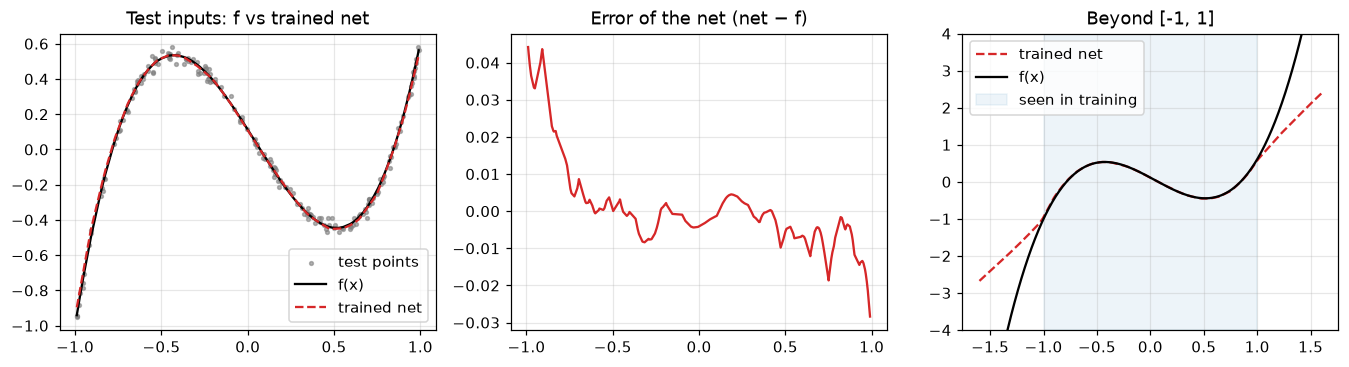

In [6]:
srt = Xte[:, 0].argsort()
x_s = Xte[srt, 0].numpy()
f_s = eval_poly(x_s, poly_c)
with torch.no_grad():
    pred = net(Xte)[srt, 0]

fig, axs = plt.subplots(1, 3, figsize=(15, 3.5))
axs[0].scatter(x_s, yte[srt, 0], s=6, c="gray", alpha=0.6, label="test points")
axs[0].plot(x_s, f_s, "k", label="f(x)")
axs[0].plot(x_s, pred, "C3--", label="trained net")
axs[0].set_title("Test inputs: f vs trained net"); axs[0].legend()
axs[1].plot(x_s, pred.numpy() - f_s, "C3")
axs[1].set_title("Error of the net (net − f)")
x_far = np.linspace(-1.6, 1.6, 400)
with torch.no_grad():
    axs[2].plot(x_far, net(col(x_far))[:, 0], "C3--", label="trained net")
axs[2].plot(x_far, eval_poly(x_far, poly_c), "k", label="f(x)")
axs[2].axvspan(-1, 1, color="C0", alpha=0.08, label="seen in training")
axs[2].set_ylim(-4, 4); axs[2].set_title("Beyond [-1, 1]"); axs[2].legend()
plt.show()

**Observations.**
- After ~40 epochs the net is at train MSE ≈ $4.5\cdot10^{-4}$, test R² ≈ 0.996. The true $f$ itself gets
  $4.0\cdot10^{-4}$ (train) and $5.0\cdot10^{-4}$ (test), so the net is at the noise level. The small train/test
  gap is just the test noise, not overfitting.
- The curves are jumpy because Adam runs on mini-batches with a constant learning rate. A decaying rate would smooth this.
- The error is largest near $x = \pm1$, where $f$ is steepest and there is data on one side only.
- Outside the training range a ReLU net is linear, so it goes on as a straight line while the cubic takes off.
  It only knows $f$ where it has seen data.

### Should we use ℓ2 regularization (weight decay)?

Weight decay pulls the weights towards zero. It trades some bias for less variance, so it only helps if the model
overfits. We try a few values of $\lambda$ (3 seeds each):

In [7]:
def compare(variants, splits, seeds=(0, 1, 2), **fit_kw):
    # variants: {label: FeedForward kwargs, optionally "wd"} -> seed-averaged final metrics, plus the last net per label
    out, nets = [], {}
    for label, kw in variants.items():
        kw = dict(kw)
        wd = kw.pop("wd", 0.0)
        last = []
        for s in seeds:
            torch.manual_seed(s)
            m = FeedForward(splits[0].shape[1], **kw)
            last.append(fit(m, splits, wd=wd, **fit_kw).iloc[-1])
        last = pd.DataFrame(last)
        nets[label] = m
        out.append({"model": label, "params": count_params(m),
                    "mse_train": last.mse_train.mean(), "mse_test": last.mse_test.mean(),
                    "mse_test_sd": last.mse_test.std(), "r2_test": last.r2_test.mean()})
    return pd.DataFrame(out).set_index("model"), nets

wd_res, _ = compare({f"wd {wd:g}": dict(wd=wd) for wd in [0, 1e-4, 1e-3, 1e-2, 1e-1]}, toy)
wd_res

,params,mse_train,mse_test,mse_test_sd,r2_test
model,,,,,
wd 0,4353,0.0004811,0.0006309,2.468e-05,0.9958
wd 0.0001,4353,0.0005103,0.0006596,7.164e-05,0.9956
wd 0.001,4353,0.001219,0.001465,0.0002451,0.9903
wd 0.01,4353,0.01186,0.0159,0.001154,0.8944
wd 0.1,4353,0.1385,0.1516,0.000118,-0.006451


**Answer: no, not here.** Without weight decay the train error is already at the noise level, so there is no
overfitting to fix. $\lambda = 10^{-4}$ changes nothing, and anything bigger only adds bias: R² drops to 0.89 at
$\lambda = 10^{-2}$, and at $\lambda = 10^{-1}$ the net collapses to the mean (R² ≈ 0). Weight decay is worth it when
the model can fit the noise (little or noisy data, many inputs or parameters, see the Concrete data below), and then
$\lambda$ should be tuned on validation data. With Adam, `AdamW` (decoupled weight decay) is usually the better choice.

## 4. Architecture and polynomial order

Defaults: 2 hidden layers × 64, ReLU, Adam (lr $10^{-3}$), 200 epochs, no weight decay, mean over 3 seeds.

**Number of hidden layers** (width 64):

In [8]:
depth_res, _ = compare({f"{d} layer(s)": dict(widths=(64,) * d) for d in [1, 2, 3, 4]}, toy)
depth_res

,params,mse_train,mse_test,mse_test_sd,r2_test
model,,,,,
1 layer(s),193,0.0004856,0.0006375,2.808e-05,0.9958
2 layer(s),4353,0.0004811,0.0006309,2.468e-05,0.9958
3 layer(s),8513,0.0004676,0.0005963,4.149e-05,0.996
4 layer(s),12673,0.0005572,0.0007407,9.151e-05,0.9951


**Activation function:**

In [9]:
activations = {"ReLU": nn.ReLU, "LeakyReLU": nn.LeakyReLU, "GELU": nn.GELU, "Tanh": nn.Tanh, "Sigmoid": nn.Sigmoid}
act_res, act_nets = compare({k: dict(act=a) for k, a in activations.items()}, toy)
act_res

,params,mse_train,mse_test,mse_test_sd,r2_test
model,,,,,
ReLU,4353,0.0004811,0.0006309,2.468e-05,0.9958
LeakyReLU,4353,0.0004912,0.0006238,3.931e-05,0.9959
GELU,4353,0.0004594,0.0005645,3.58e-06,0.9963
Tanh,4353,0.0004475,0.0005803,1.988e-05,0.9961
Sigmoid,4353,0.005403,0.006766,0.001779,0.9551


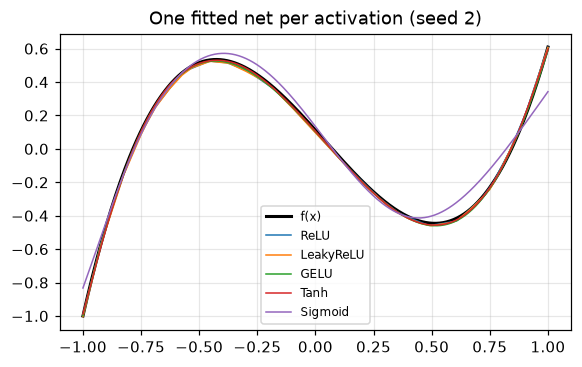

In [10]:
xs_t = col(xs)
plt.figure(figsize=(6, 3.5))
plt.plot(xs, eval_poly(xs, poly_c), "k", lw=2, label="f(x)")
for label, m in act_nets.items():
    with torch.no_grad():
        plt.plot(xs, m(xs_t)[:, 0], lw=1, label=label)
plt.title("One fitted net per activation (seed 2)"); plt.legend(fontsize=8)
plt.show()

**Number of parameters** (2 hidden layers of width $m$):

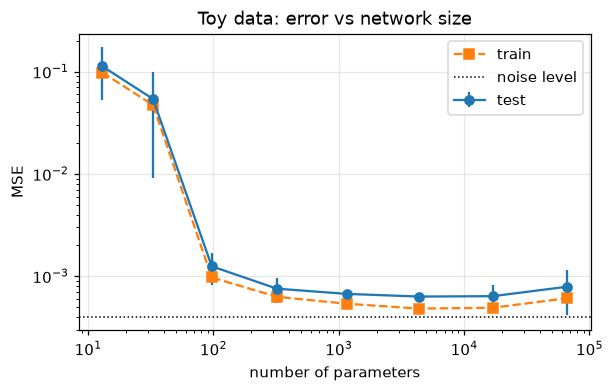

,params,mse_train,mse_test,mse_test_sd,r2_test
model,,,,,
width 2,13,0.09794,0.1127,0.06024,0.2516
width 4,33,0.04706,0.05392,0.04473,0.6419
width 8,97,0.0009695,0.001246,0.0004292,0.9917
width 16,321,0.0006272,0.0007531,0.0002087,0.995
width 32,1153,0.0005363,0.0006698,5.438e-05,0.9956
width 64,4353,0.0004811,0.0006309,2.468e-05,0.9958
width 128,16897,0.00049,0.0006358,0.0001807,0.9958
width 256,66561,0.0006083,0.0007874,0.0003723,0.9948


In [11]:
width_res, _ = compare({f"width {w}": dict(widths=(w, w)) for w in [2, 4, 8, 16, 32, 64, 128, 256]}, toy)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(width_res.params, width_res.mse_test, yerr=width_res.mse_test_sd, marker="o", label="test")
ax.plot(width_res.params, width_res.mse_train, "s--", label="train")
ax.axhline(SIGMA**2, color="k", ls=":", lw=1, label="noise level")
ax.set(xscale="log", yscale="log", xlabel="number of parameters", ylabel="MSE", title="Toy data: error vs network size")
ax.legend(); plt.show()
width_res

**Observations (p = 3).**
- **Depth:** 1 to 4 hidden layers all hit the noise level, and the differences are within the seed spread. One hidden
  layer (193 parameters) is plenty for a cubic. With the same learning rate and epochs, 4 layers is a bit worse and less stable.
- **Activation:** ReLU, LeakyReLU, GELU and Tanh are all at the noise level, with the smooth ones (GELU, Tanh) slightly
  ahead: the target is smooth, while a ReLU fit has small kinks. Sigmoid is 10× worse and the least stable. It saturates,
  isn't zero-centred and its derivative is at most 1/4, so gradients shrink layer by layer and 200 epochs aren't enough.
- **Width:** $m = 2$ and $4$ underfit badly and depend a lot on the seed (too few linear pieces, and a few dead ReLUs
  wipe out most of the capacity). From $m = 8$ (~100 parameters) we are close to the noise level, and past $m \approx 64$
  nothing improves. Even 66k parameters for 800 points does **not** overfit: with this little noise, gradient training
  still ends up at a smooth function.

**Polynomial order $p$.** Same recipe for $p \in \{1, 3, 5, 9, 15, 21\}$, with the default net (2×64) and a deeper,
wider one (3×128):

In [12]:
ORDERS = [1, 3, 5, 9, 15, 21]
archs = {"2x64": dict(widths=(64, 64)), "3x128": dict(widths=(128, 128, 128))}
parts, by_order = [], {}
for p in ORDERS:
    c, splits = toy_data(p)
    res, nets = compare(archs, splits)
    parts.append(res.assign(p=p).reset_index())
    by_order[p] = (c, nets)
order_res = pd.concat(parts).pivot(index="p", columns="model", values=["mse_train", "mse_test", "r2_test"])
order_res

mse_train            mse_test           r2_test       
model      2x64     3x128      2x64     3x128    2x64  3x128
p                                                           
1      0.000425 0.0005117 0.0005287 0.0006278  0.9981 0.9977
3     0.0004811 0.0005257 0.0006309 0.0006102  0.9958 0.9959
5     0.0009284 0.0008732  0.001023  0.001095  0.9946 0.9942
9      0.008146  0.003594  0.008113  0.003349  0.9622 0.9844
15      0.02391  0.009353   0.02822  0.009442  0.8445  0.948
21      0.09901   0.01398    0.1143   0.02297  0.3456 0.8684

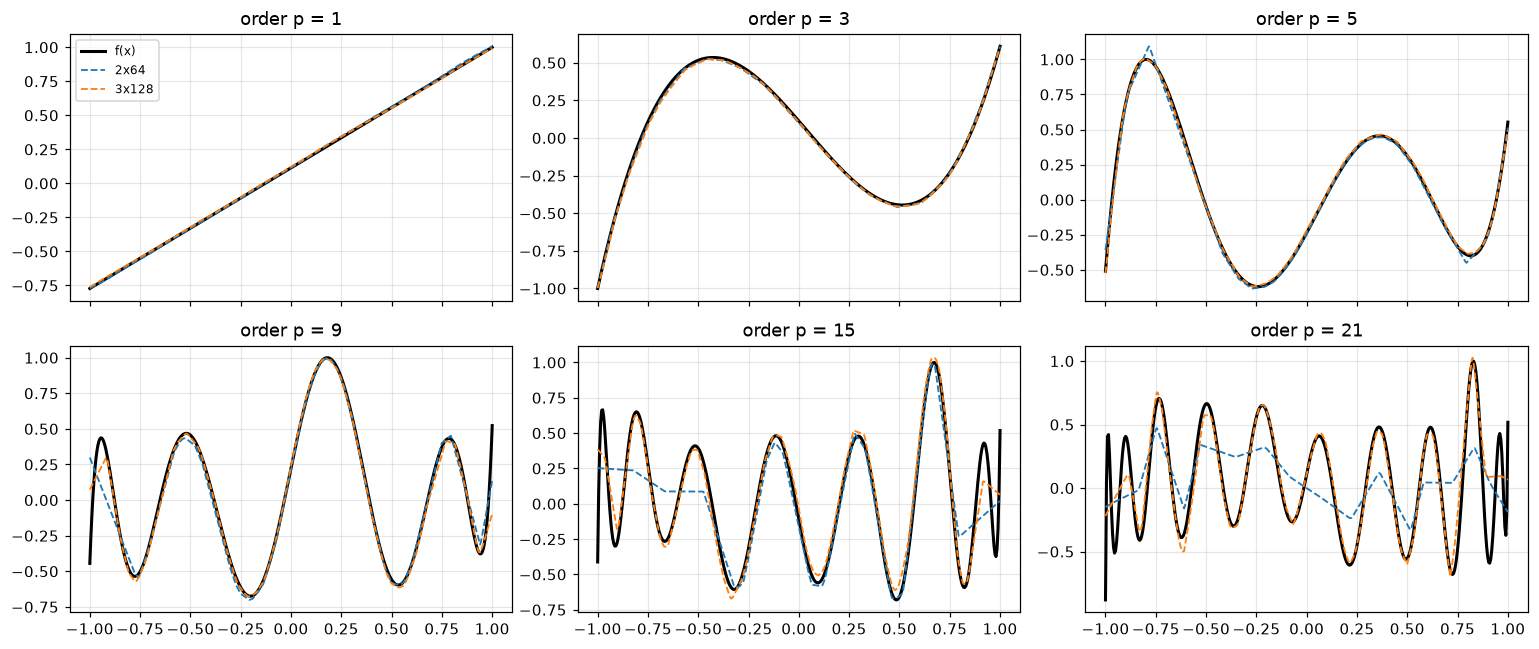

In [13]:
fig, axs = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, p in zip(axs.flat, ORDERS):
    c, nets = by_order[p]
    ax.plot(xs, eval_poly(xs, c), "k", lw=2, label="f(x)")
    for label, m in nets.items():
        with torch.no_grad():
            ax.plot(xs, m(xs_t)[:, 0], "--", lw=1.2, label=label)
    ax.set_title(f"order p = {p}")
axs[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observations.**
- Up to $p = 5$ both nets reach the noise level. From $p = 9$ the 2×64 net underfits (train ≈ test error, so it's
  bias, not variance), and at $p = 21$ it basically fails (R² 0.35) and smooths over most of the wiggles.
- The 3×128 net is 2-5× better for $p \ge 9$ and still reaches R² 0.87 at $p = 21$. A ReLU net needs roughly one linear
  piece per bend of $f$, so more wiggles need more capacity, and adding depth multiplies the number of pieces much
  faster than adding width.
- Both nets lose the outermost wiggles first. The roots are densest near $\pm1$, so $f$ oscillates fastest exactly
  where there is data on one side only.
- The net never sees the coefficients. In the monomial basis they blow up with $p$ (around $10^6$ for $p = 21$), so
  fitting the polynomial directly would be badly conditioned. For the net, only how wiggly $f$ is matters.

## 5. Real data: UCI Concrete Compressive Strength

TODO: Is this one of the datasets we used in our previous lab (/Users/tomibozak/Projects/EMAI/IML/emai-ml)? If no, could we do this exercise equally well with one of our datasets previously used? Because I am worried classmates will do the same thing with claude code and will use the same dataset and prof. wanted us to use different datasets. But if we use one of our's than we're good. Let's briefly discuss this before changes regarding this.

[Concrete Compressive Strength](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength)
(Yeh, 1998): 1,030 concrete mixtures with 8 numeric inputs (cement, slag, fly ash, water, superplasticizer, coarse and
fine aggregate in kg/m³, and age in days). The target is compressive strength in MPa. Strength depends nonlinearly on
things like age and the water/cement ratio, so an MLP should beat a linear model.

Same 80/20 split. Inputs and target are standardized with training-set statistics; the net trains on the standardized
target, and we also report RMSE in MPa. Ordinary least squares is the baseline.

In [14]:
csv = Path("data/concrete.csv")
if not csv.exists():
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=165)
    csv.parent.mkdir(exist_ok=True)
    pd.concat([ds.data.features, ds.data.targets], axis=1).to_csv(csv, index=False)
mix = pd.read_csv(csv)
feats_raw, strength = mix.iloc[:, :-1].to_numpy(), mix.iloc[:, -1].to_numpy()
print(f"{mix.shape[0]} mixtures, {mix.shape[1] - 1} input features")
display(mix.describe().T[["mean", "std", "min", "max"]])

f_tr, f_te, s_tr, s_te = train_test_split(feats_raw, strength, test_size=0.2, random_state=0)
sx, sy = StandardScaler().fit(f_tr), StandardScaler().fit(s_tr[:, None])
MPA = sy.scale_[0]  # std of the training target in MPa
real = (col(sx.transform(f_tr)), col(sy.transform(s_tr[:, None])),
        col(sx.transform(f_te)), col(sy.transform(s_te[:, None])))

def to_mpa(mse):  # MSE on the standardized target -> RMSE in MPa
    return np.sqrt(mse) * MPA

lin = LinearRegression().fit(real[0], real[1])
lin_mse = F.mse_loss(torch.tensor(lin.predict(real[2]), dtype=torch.float32), real[3]).item()
print(f"OLS baseline on test: RMSE {to_mpa(lin_mse):.2f} MPa, R2 {lin.score(real[2], real[3]):.3f}")

1030 mixtures, 8 input features


,mean,std,min,max
Cement,281.2,104.5,102,540
Blast Furnace Slag,73.9,86.28,0,359.4
Fly Ash,54.19,64,0,200.1
Water,181.6,21.35,121.8,247
Superplasticizer,6.205,5.974,0,32.2
Coarse Aggregate,972.9,77.75,801,1145
Fine Aggregate,773.6,80.18,594,992.6
Age,45.66,63.17,1,365
Concrete compressive strength,35.82,16.71,2.33,82.6


OLS baseline on test: RMSE 9.78 MPa, R2 0.637


**Step 2 again: the untrained net.** With 8 inputs we can't plot the function itself, so we plot predicted vs
measured strength on the training set.

4801 parameters | train RMSE before training: 16.8 MPa


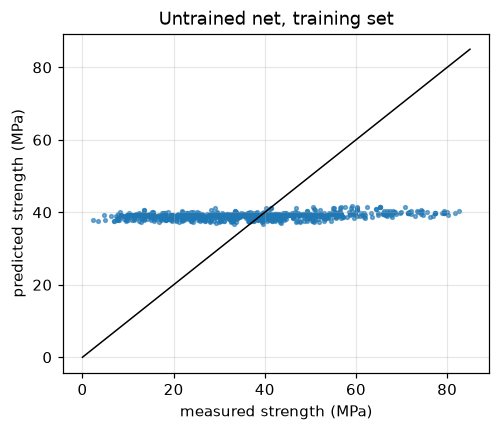

In [15]:
def scatter_pred(nets, X, y, titles):
    fig, axs = plt.subplots(1, len(nets), figsize=(5 * len(nets), 4), squeeze=False)
    actual = sy.inverse_transform(y.numpy())[:, 0]
    for ax, m, t in zip(axs[0], nets, titles):
        with torch.no_grad():
            guess = sy.inverse_transform(m(X).numpy())[:, 0]
        ax.scatter(actual, guess, s=6, alpha=0.6)
        ax.plot([0, 85], [0, 85], "k", lw=1)
        ax.set(xlabel="measured strength (MPa)", ylabel="predicted strength (MPa)", title=t)
    plt.show()

torch.manual_seed(0)
rnet = FeedForward(d_in=8)
print(f"{count_params(rnet)} parameters | train RMSE before training: {to_mpa(score(rnet, real[0], real[1])[0]):.1f} MPa")
scatter_pred([rnet], real[0], real[1], ["Untrained net, training set"])

**Step 3 again: training.** 300 epochs, everything else as for the polynomial.

ep   1  train: MSE 6.58e-01, R2 0.3415   test: MSE 6.28e-01, R2 0.3271
ep   2  train: MSE 4.17e-01, R2 0.5827   test: MSE 3.78e-01, R2 0.5953
ep   3  train: MSE 3.39e-01, R2 0.6614   test: MSE 3.17e-01, R2 0.6600
ep   4  train: MSE 2.81e-01, R2 0.7188   test: MSE 2.63e-01, R2 0.7182
ep   5  train: MSE 2.33e-01, R2 0.7673   test: MSE 2.29e-01, R2 0.7546


ep  50  train: MSE 4.56e-02, R2 0.9544   test: MSE 1.09e-01, R2 0.8828


ep 100  train: MSE 3.57e-02, R2 0.9643   test: MSE 9.85e-02, R2 0.8944


ep 150  train: MSE 2.52e-02, R2 0.9748   test: MSE 9.75e-02, R2 0.8955


ep 200  train: MSE 2.44e-02, R2 0.9756   test: MSE 9.08e-02, R2 0.9027


ep 250  train: MSE 1.89e-02, R2 0.9811   test: MSE 8.98e-02, R2 0.9038


ep 300  train: MSE 2.02e-02, R2 0.9798   test: MSE 8.68e-02, R2 0.9069

after 300 epochs: RMSE train 2.39 / test 4.95 MPa, test R2 0.907


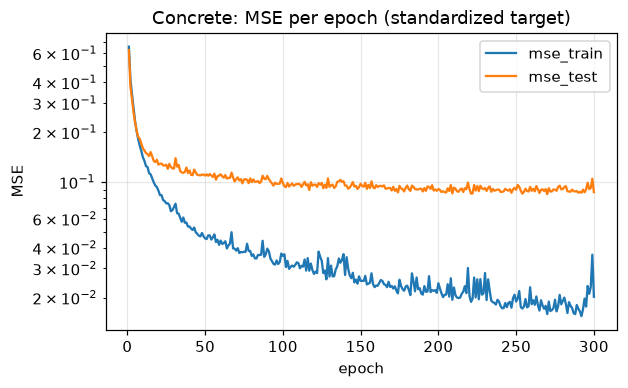

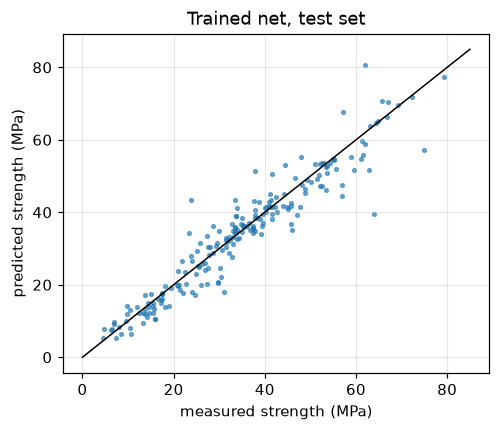

In [16]:
R_EPOCHS = 300
rlog = fit(rnet, real, epochs=R_EPOCHS, log_every=50)
end = rlog.iloc[-1]
print(f"\nafter {R_EPOCHS} epochs: RMSE train {to_mpa(end.mse_train):.2f} / test {to_mpa(end.mse_test):.2f} MPa, test R2 {end.r2_test:.3f}")
plot_history(rlog, "Concrete: MSE per epoch (standardized target)")
scatter_pred([rnet], real[2], real[3], ["Trained net, test set"])

**Observations.**
- Untrained, the net predicts about 39 MPa for every mixture, i.e. roughly the mean.
- The train MSE keeps going down, while the test MSE levels off after ~100-150 epochs. Final test RMSE is ~4.9 MPa
  (R² ≈ 0.91), against 9.8 MPa (R² 0.64) for linear regression. The nonlinearity pays off: strength saturates with
  age and depends on ratios like water/cement, which a linear model can't express.
- Unlike the toy data there is a clear gap (train RMSE ~2.4 vs test ~4.9 MPa): with 824 noisy 8-D samples the net partly
  memorizes the training set. The test loss doesn't go back up within 300 epochs, though, so it isn't hurting yet.
  The biggest errors are on the rare high-strength samples.

In [17]:
def in_mpa(res):  # RMSE in MPa; the _sd column is the seed std (delta method)
    return res.assign(rmse_train=to_mpa(res.mse_train), rmse_test=to_mpa(res.mse_test),
                      rmse_test_sd=MPA * res.mse_test_sd / (2 * np.sqrt(res.mse_test)))[
        ["params", "rmse_train", "rmse_test", "rmse_test_sd", "r2_test"]]

big = (128, 128, 128)
rwd, _ = compare({f"{a}, wd {wd:g}": dict(widths=w, wd=wd)
                  for a, w in [("2x64", (64, 64)), ("3x128", big)] for wd in [0, 1e-3, 1e-2, 1e-1]},
                 real, epochs=R_EPOCHS)
in_mpa(rwd)

,params,rmse_train,rmse_test,rmse_test_sd,r2_test
model,,,,,
"2x64, wd 0",4801,2.381,4.885,0.171,0.9094
"2x64, wd 0.001",4801,2.869,5.057,0.1701,0.9029
"2x64, wd 0.01",4801,4.415,5.341,0.2243,0.8917
"2x64, wd 0.1",4801,7.776,7.391,0.02442,0.7926
"3x128, wd 0",34305,1.827,4.661,0.1132,0.9175
"3x128, wd 0.001",34305,2.454,4.939,0.04476,0.9074
"3x128, wd 0.01",34305,3.81,5.109,0.03038,0.9009
"3x128, wd 0.1",34305,7.499,7.254,0.06027,0.8002


**Answer.** Here weight decay is at least worth trying, since there is a real train/test gap. In our runs it still
doesn't help: for both 2×64 and 3×128, a larger $\lambda$ raises the train error a lot and the test error a little, and
the unregularized 3×128 is best (~4.7 MPa). The gap seems harmless (the test loss never turns up), and most of the
remaining error is probably noise we can't remove (measurement error, factors missing from the 8 features).
So: tune $\lambda$ on a validation set rather than assume it helps. Early stopping or more data are the other options.

**Step 4 again: depth, activation and size.**

In [18]:
rdepth, _ = compare({f"{d} layer(s)": dict(widths=(64,) * d) for d in [1, 2, 3, 4]}, real, epochs=R_EPOCHS)
in_mpa(rdepth)

,params,rmse_train,rmse_test,rmse_test_sd,r2_test
model,,,,,
1 layer(s),641,3.411,5.256,0.1482,0.8951
2 layer(s),4801,2.381,4.885,0.171,0.9094
3 layer(s),8961,2.111,4.826,0.4883,0.9116
4 layer(s),13121,2.083,4.954,0.2153,0.9068


In [19]:
ract, _ = compare({k: dict(act=a) for k, a in activations.items()}, real, epochs=R_EPOCHS)
in_mpa(ract)

,params,rmse_train,rmse_test,rmse_test_sd,r2_test
model,,,,,
ReLU,4801,2.381,4.885,0.171,0.9094
LeakyReLU,4801,2.496,5.008,0.2144,0.9048
GELU,4801,2.987,5.153,0.17,0.8992
Tanh,4801,3.006,5.367,0.1033,0.8906
Sigmoid,4801,4.993,5.897,0.1165,0.8679


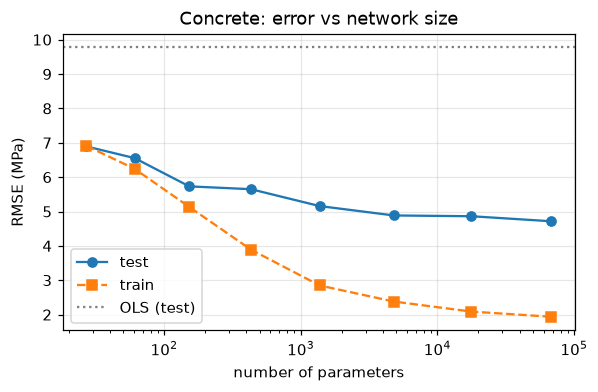

,params,rmse_train,rmse_test,rmse_test_sd,r2_test
model,,,,,
width 2,27,6.911,6.894,0.03716,0.8195
width 4,61,6.241,6.553,0.3049,0.837
width 8,153,5.132,5.731,0.395,0.8753
width 16,433,3.891,5.649,0.4338,0.8788
width 32,1377,2.849,5.158,0.103,0.899
width 64,4801,2.381,4.885,0.171,0.9094
width 128,17793,2.088,4.862,0.1139,0.9102
width 256,68353,1.937,4.716,0.3101,0.9156


In [20]:
rwidth, _ = compare({f"width {w}": dict(widths=(w, w)) for w in [2, 4, 8, 16, 32, 64, 128, 256]}, real, epochs=R_EPOCHS)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(rwidth.params, to_mpa(rwidth.mse_test), "o-", label="test")
ax.plot(rwidth.params, to_mpa(rwidth.mse_train), "s--", label="train")
ax.axhline(to_mpa(lin_mse), color="gray", ls=":", label="OLS (test)")
ax.set(xscale="log", xlabel="number of parameters", ylabel="RMSE (MPa)", title="Concrete: error vs network size")
ax.legend(); plt.show()
in_mpa(rwidth)

**Observations.**
- **Depth:** one hidden layer is clearly worse (5.3 MPa), 2-3 layers are best (~4.8-4.9 MPa), a 4th doesn't help.
- **Activation:** the opposite of the toy problem. ReLU and LeakyReLU come first, then GELU and Tanh, and Sigmoid
  is last (5.9 MPa). The train errors explain it: in 300 epochs the smooth and saturating activations don't fit the
  training set as well (Tanh 3.0, Sigmoid 5.0 vs ReLU 2.4 MPa), so it's mostly about how easy they are to optimize.
- **Size:** the test error goes down steadily with size, from 6.9 MPa (27 parameters, already much better than OLS)
  to 4.7 MPa (68k parameters). The train error drops to 1.9 MPa, so the gap grows, but the test error never turns up.
  No U-shaped bias-variance curve in this range: bigger nets generalize at least as well. Above ~5k parameters the
  gains are about the size of the seed spread.
- Caveat: as the lab asks, all of this is compared on the test set. To actually pick a model we would use a
  validation split or cross-validation and keep the test set for the final number.

## Summary

- An MLP trained with MSE and Adam fits a low-order polynomial down to the noise level in a few dozen epochs. Outside
  the training range a ReLU net just continues linearly, so it only learns $f$ where it has data.
- Weight decay isn't needed when the model doesn't overfit (toy data); there it only adds bias. On the noisier real
  data there is a train/test gap, but weight decay still didn't lower the test error. Tune it, don't assume it.
- Capacity has to match the target. A cubic needs ~100 parameters, an order-21 polynomial needs a deeper/wider net,
  and depth adds capacity more cheaply than width.
- Activations matter mainly through optimization: Sigmoid is always worst, ReLU-type activations train fastest, and
  smooth ones help a little on smooth 1-D targets.
- On Concrete, a 2-3 layer MLP roughly halves the error of linear regression (≈ 4.7-4.9 vs 9.8 MPa RMSE, R² ≈ 0.91 vs
  0.64), and bigger nets kept doing better in the range we tried, despite the growing train/test gap.